In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import os

In [2]:
# Load dataset
df = pd.read_csv("../data/bank_churn.csv")

# Separate features and target
X = df.drop(columns=["Exited", "id", "CustomerId", "Surname"])
y = df["Exited"]

# Recreate stratified splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Load fitted preprocessing pipeline
preprocessor = joblib.load("../models/preprocessor.joblib")

# Transform datasets
X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (115523, 13)
Validation: (24755, 13)
Testing: (24756, 13)


In [3]:
lr_model=LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
lr_model.fit(X_train_processed,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [7]:
lr_predictions=lr_model.predict(X_val_processed)

In [5]:
lr_probabilities = lr_model.predict_proba(X_val_processed)[:, 1]

In [8]:

lr_results = {
    "Model": "Logistic Regression",
    "ROC-AUC": roc_auc_score(y_val, lr_probabilities),
    "Accuracy": accuracy_score(y_val, lr_predictions),
    "Precision": precision_score(y_val, lr_predictions),
    "Recall": recall_score(y_val, lr_predictions),
    "F1-Score": f1_score(y_val, lr_predictions)
}

lr_results

{'Model': 'Logistic Regression',
 'ROC-AUC': 0.8197978019104091,
 'Accuracy': 0.7539486972328823,
 'Precision': 0.4503203261502621,
 'Recall': 0.7380679648720886,
 'F1-Score': 0.5593575924184331}

In [9]:
lr_cm = confusion_matrix(y_val, lr_predictions)

print("Confusion Matrix:")
print(lr_cm)

Confusion Matrix:
[[14798  4719]
 [ 1372  3866]]


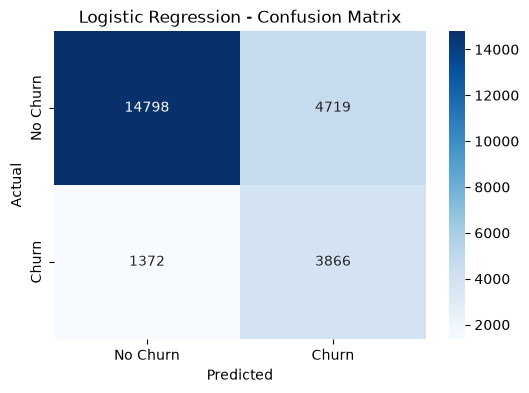

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [11]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [12]:
rf_predictions = rf_model.predict(X_val_processed)
rf_probabilities = rf_model.predict_proba(X_val_processed)[:, 1]

In [13]:
rf_results = {
    "Model": "Random Forest",
    "ROC-AUC": roc_auc_score(y_val, rf_probabilities),
    "Accuracy": accuracy_score(y_val, rf_predictions),
    "Precision": precision_score(y_val, rf_predictions),
    "Recall": recall_score(y_val, rf_predictions),
    "F1-Score": f1_score(y_val, rf_predictions)
}

rf_results

{'Model': 'Random Forest',
 'ROC-AUC': 0.8738862789908164,
 'Accuracy': 0.846091698646738,
 'Precision': 0.6298181818181818,
 'Recall': 0.6613211149293623,
 'F1-Score': 0.6451853231514248}

In [14]:
comparison = pd.DataFrame([
    lr_results,
    rf_results
])

comparison

,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.819798,0.753949,0.450320,0.738068,0.559358
1,Random Forest,0.873886,0.846092,0.629818,0.661321,0.645185


In [15]:

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_processed, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [16]:
xgb_predictions = xgb_model.predict(X_val_processed)
xgb_probabilities = xgb_model.predict_proba(X_val_processed)[:, 1]

In [17]:
xgb_results = {
    "Model": "XGBoost",
    "ROC-AUC": roc_auc_score(y_val, xgb_probabilities),
    "Accuracy": accuracy_score(y_val, xgb_predictions),
    "Precision": precision_score(y_val, xgb_predictions),
    "Recall": recall_score(y_val, xgb_predictions),
    "F1-Score": f1_score(y_val, xgb_predictions)
}

xgb_results

{'Model': 'XGBoost',
 'ROC-AUC': 0.889798753489752,
 'Accuracy': 0.8675823066047263,
 'Precision': 0.7540176257128045,
 'Recall': 0.555364642993509,
 'F1-Score': 0.6396218117854002}

In [18]:
comparison = pd.DataFrame([
    lr_results,
    rf_results,
    xgb_results
])

comparison = comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

comparison

,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.889799,0.867582,0.754018,0.555365,0.639622
1,Random Forest,0.873886,0.846092,0.629818,0.661321,0.645185
2,Logistic Regression,0.819798,0.753949,0.450320,0.738068,0.559358


In [19]:
# Generate test predictions
lr_test_prob = lr_model.predict_proba(X_test_processed)[:, 1]
rf_test_prob = rf_model.predict_proba(X_test_processed)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

test_models = {
    "Logistic Regression": (lr_model, lr_test_prob),
    "Random Forest": (rf_model, rf_test_prob),
    "XGBoost": (xgb_model, xgb_test_prob)
}

test_results = []

for name, (model, probabilities) in test_models.items():

    predictions = model.predict(X_test_processed)

    test_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

test_comparison = pd.DataFrame(test_results)

test_comparison

,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.814489,0.754282,0.450218,0.729477,0.556794
1,Random Forest,0.872376,0.845896,0.628685,0.663612,0.645677
2,XGBoost,0.887555,0.865043,0.746812,0.547919,0.632089


In [20]:
import os
import joblib


os.makedirs("../models", exist_ok=True)


joblib.dump(lr_model, "../models/logistic_regression.joblib")
joblib.dump(rf_model, "../models/random_forest.joblib")
joblib.dump(xgb_model, "../models/xgboost.joblib")

print("All three models saved successfully!")

All three models saved successfully!
